# Market Basket Analysis
**Data Analytics Internship · Project 06**

Find products purchased together and use the strongest rules to design cross-sell tests. Each completed invoice is a basket, and each product counts once per basket.

**Source** Chen, D. (2015). [Online Retail](https://doi.org/10.24432/C5BW33), UCI Machine Learning Repository, CC BY 4.0. The bundled extract keeps UK rows and five columns from the original workbook.

In [11]:
from collections import Counter
from itertools import combinations
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd

raw = pd.read_csv(Path("data") / "uk_retail.csv.gz",
                  dtype={"InvoiceNo": str, "StockCode": str})
raw["StockCode"] = raw["StockCode"].str.strip().str.upper()
raw["Description"] = raw["Description"].str.strip()
lines = raw.loc[
    raw["InvoiceNo"].str.fullmatch(r"[0-9]+", na=False)
    & raw["StockCode"].str.fullmatch(r"[0-9]{5}[A-Z]*", na=False)
    & raw["Quantity"].gt(0)
    & raw["UnitPrice"].gt(0)
    & raw["Description"].fillna("").ne("")
].copy()
baskets = lines.groupby("InvoiceNo")["StockCode"].agg(lambda codes: set(codes))
labels = (lines.groupby("StockCode")["Description"]
          .agg(lambda descriptions: descriptions.value_counts().index[0]).to_dict())
total = len(baskets)
assert total > 0
print(f"UK input lines: {len(raw):,} | Eligible product lines: {len(lines):,}")
print(f"Baskets: {total:,} | Distinct product codes: {len(labels):,}")

UK input lines: 495,478 | Eligible product lines: 483,971
Baskets: 17,901 | Distinct product codes: 3,785


## 1. Mine frequent itemsets with Apriori

Use a minimum support of 1%. First count single products. Then consider pairs made only from frequent products, since a pair cannot occur more often than either product alone. This analysis stops at pairs to keep cross-sell recommendations easy to act on.

The product-code filter is a heuristic for excluding fees and administrative lines. Keep single-item baskets in the denominator.

In [12]:
minimum_support = 0.01
minimum_count = ceil(minimum_support * total)

single_counts = Counter(code for basket in baskets for code in basket)
frequent_singles = {code for code, count in single_counts.items()
                    if count >= minimum_count}
pair_counts = Counter(pair for basket in baskets
                      for pair in combinations(sorted(basket & frequent_singles), 2))
frequent_pairs = {pair: count for pair, count in pair_counts.items()
                  if count >= minimum_count}
print(f"Minimum baskets per itemset: {minimum_count:,}")
print(f"Frequent products: {len(frequent_singles):,} | Frequent pairs: {len(frequent_pairs):,}")
assert frequent_pairs

Minimum baskets per itemset: 180
Frequent products: 827 | Frequent pairs: 1,041


## 2. Generate directional rules

- **Support** is the fraction of all baskets with both products.
- **Confidence** for A → B is the fraction of A baskets that also contain B.
- **Lift** compares that confidence with how often B appears overall. A lift of 3 means B is three times as common in A baskets as in all baskets.

Keep rules with confidence of at least 30% and lift above 1. Rank by lift, then support.

In [13]:
rule_rows = []
for (a, b), count in frequent_pairs.items():
    for first, second in [(a, b), (b, a)]:
        confidence = count / single_counts[first]
        lift = confidence / (single_counts[second] / total)
        rule_rows.append({"A": labels[first], "B": labels[second], "A code": first,
                          "B code": second, "Baskets": count, "Support": count / total,
                          "Confidence": confidence, "Lift": lift})
rules = (pd.DataFrame(rule_rows)
         .query("Confidence >= 0.30 and Lift > 1")
         .sort_values(["Lift", "Support", "A code", "B code"], ascending=[False, False, True, True])
         .reset_index(drop=True))
print(f"Rules passing all thresholds: {len(rules):,}")
print(rules[["A", "B", "Baskets", "Support", "Confidence", "Lift"]].head(8)
      .to_string(index=False, formatters={"Support": "{:.1%}".format,
                                         "Confidence": "{:.1%}".format,
                                         "Lift": "{:.2f}".format}))
assert len(rules) > 0 and rules["Confidence"].between(0, 1).all()

Rules passing all thresholds: 838
                   A                    B  Baskets Support Confidence  Lift
 HERB MARKER PARSLEY   HERB MARKER CHIVES      187    1.0%      82.0% 72.32
  HERB MARKER CHIVES  HERB MARKER PARSLEY      187    1.0%      92.1% 72.32
HERB MARKER ROSEMARY    HERB MARKER THYME      214    1.2%      92.6% 72.10
   HERB MARKER THYME HERB MARKER ROSEMARY      214    1.2%      93.0% 72.10
   HERB MARKER THYME  HERB MARKER PARSLEY      207    1.2%      90.0% 70.66
 HERB MARKER PARSLEY    HERB MARKER THYME      207    1.2%      90.8% 70.66
   HERB MARKER THYME   HERB MARKER CHIVES      184    1.0%      80.0% 70.55
  HERB MARKER CHIVES    HERB MARKER THYME      184    1.0%      90.6% 70.55


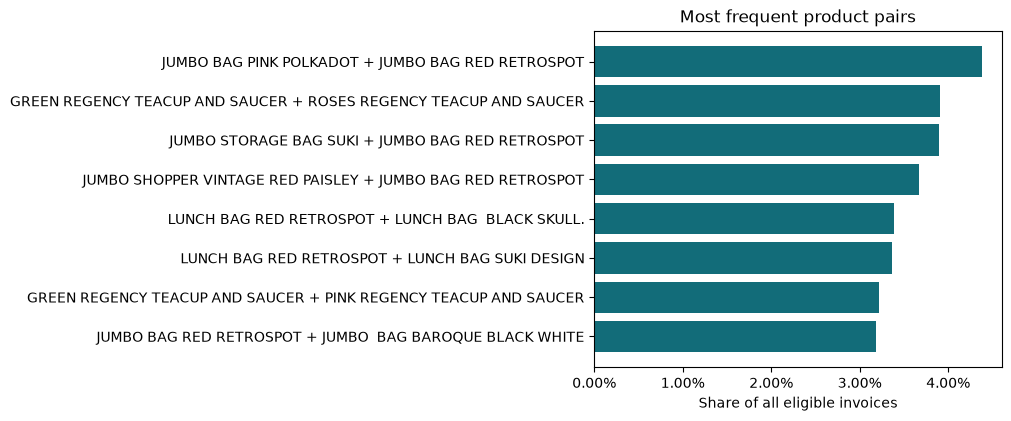

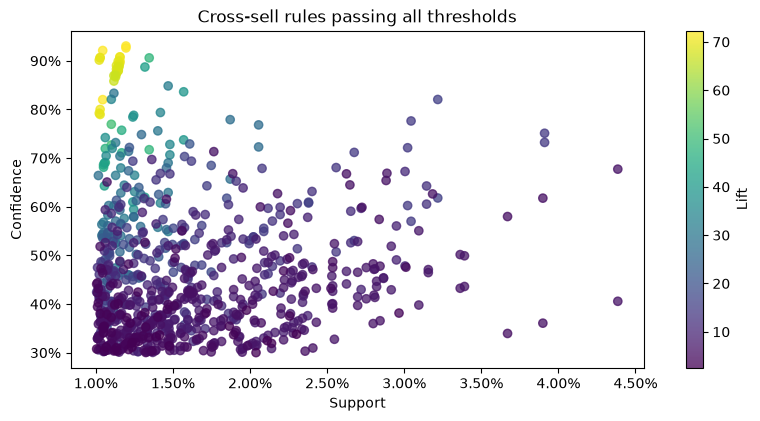

In [14]:
top_pairs = sorted(frequent_pairs.items(), key=lambda item: (-item[1], item[0]))[:8]
fig, ax = plt.subplots(figsize=(10, 4.1), constrained_layout=True)
ax.barh([f"{labels[a]} + {labels[b]}" for (a, b), _ in reversed(top_pairs)],
        [count / total for _, count in reversed(top_pairs)], color="#126c79")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Most frequent product pairs", xlabel="Share of all eligible invoices")
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.1), constrained_layout=True)
points = ax.scatter(rules["Support"], rules["Confidence"], c=rules["Lift"],
                    cmap="viridis", alpha=0.75)
fig.colorbar(points, ax=ax, label="Lift")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Cross-sell rules passing all thresholds",
       xlabel="Support", ylabel="Confidence")
plt.show()

## 3. Propose two business tests

Use a high-lift directional rule for a targeted recommendation and the most frequent pair for a higher-reach merchandising test.

In [15]:
best = rules.iloc[0]
print(f"Cart recommendation: If a basket contains {best['A']}, suggest {best['B']}.")
print(f"Historical confidence: {best['Confidence']:.1%} | Lift: {best['Lift']:.2f} | "
      f"Joint baskets: {best['Baskets']:,}")
(a, b), count = top_pairs[0]
print(f"Bundle or shared placement: {labels[a]} + {labels[b]} ({count:,} baskets).")

Cart recommendation: If a basket contains HERB MARKER PARSLEY, suggest HERB MARKER CHIVES.
Historical confidence: 82.0% | Lift: 72.32 | Joint baskets: 187
Bundle or shared placement: JUMBO BAG PINK POLKADOT + JUMBO BAG RED RETROSPOT (785 baskets).


Randomize shoppers between the existing experience and the proposed recommendation. Measure add-on purchase rate and gross margin per order. These associations describe historical UK purchases from one retailer. Seasonality, stock availability, and wholesale orders could affect the results.